### Authors:
Dawid Łuka 164203

Jakub Krzoska 164189

# Wikipedia Article Recommender

**Goal.** Given a list of Wikipedia articles a user has visited, recommend other articles they are likely to find interesting, each with a relevance **score**.

**Domain.** The corpus focuses on psychiatry and neurology. It was built from 9 seed articles: ADHD, Major depressive disorder, Bipolar disorder, Schizophrenia, Autism, Generalized anxiety disorder, PTSD, Alzheimer's disease and Epilepsy.

**Pipeline.**
1. **Crawling & scraping:** collect ~1,100 articles with a breadth-first crawler (`crawler.py`, `scraper.py`).
2. **Preprocessing:** lemmatize the text with spaCy and save it as Parquet (`preprocessing.py`).
3. **Recommendation:** represent articles as TF-IDF vectors and rank them by cosine similarity to the user profile (`recommender.py`).
4. **Explanation:** break each score down into per-word contributions.


## Step 1 – Crawling and scraping

**Tool choice.** The course labs used `requests` + BeautifulSoup. This project uses **Playwright** instead: one of the author (Dawid) already works with it for end-to-end testing, and its locator API (CSS selectors, `inner_text`, `evaluate_all`) works just as well for scraping. The trade-off is speed: a full headless browser is slower than plain HTTP requests, which is acceptable for ~1,100 pages.

**Scraping a single article** (`scrape_article`):
- Pages are loaded with **Playwright** (headless Chromium).
- The title is taken from `#firstHeading`. The text is built only from the body paragraphs (`.mw-parser-output > section > p`), so infoboxes, tables, navigation boxes and reference lists are skipped.
- Citation markers such as `[12]` or `[citation needed]` are removed with a regular expression.
- Outgoing links are collected **only from these paragraphs**. Only links to other English Wikipedia articles are kept: links to special pages (`File:`, `Category:`, `Help:` …) are dropped, and section anchors (`#...`) are cut off. Duplicates are removed.

**Crawling** (`crawl`), breadth-first search:
- A queue (`deque`) starts with the 9 seed URLs. Articles are processed in FIFO order, and each newly found link is appended to the end of the queue.
- A `visited` set of URLs makes sure no page is queued twice.
- A `seen_titles` set removes duplicates caused by **redirects**: different URLs can lead to the same article.
- A random delay of 0.5–1.5 s between requests keeps the load on Wikipedia's servers low.
- Pages that fail to load are skipped (`try/except`), so one error does not stop the crawl.
- The crawl stops after **1,100 articles**. They are saved to `output/articles.parquet` with the columns `title`, `url`, `text` and `links`.

**Limitation – topic drift.** BFS follows every link, so with each level it moves further from the seed topics. About 79% of the articles are on-topic. The rest are unrelated pages reached through general links (e.g. *Santa Claus*, *Cat*), as shown in the t-SNE map in section 5.

## Step 2 – Preprocessing

**Tool choice.** The course labs used NLTK. This project uses **spaCy** to try an alternative library. One practical advantage: spaCy runs POS tagging and lemmatization in a single pipeline, so each word gets the lemma for its actual part of speech. NLTK's `WordNetLemmatizer` treats every word as a noun unless the POS tag is passed manually.

Each article's text is turned into a list of lemmas with spaCy (`en_core_web_sm`) in `preprocess(text, nlp)`:
- The parser and named-entity recognizer are disabled. Only the tokenizer, POS tagger and lemmatizer are needed, so processing is faster.
- For each token, the **lemma** is taken and lowercased (*diagnosed → diagnose*, *disorders → disorder*).
- Only alphabetic tokens are kept (`is_alpha`): numbers and punctuation are dropped.
- **Stop words** (spaCy's built-in list: *the*, *of*, *and* …) are removed.
- The lemmas are joined with spaces into one string (column `lemmas`). This is the input format expected by `TfidfVectorizer`.

**Why lemmatization, not stemming.** A stemmer cuts word endings by rules and often produces non-words (*diagnosis → diagnosi*). Lemmas are real dictionary words, so the words shown in the prediction-breakdown charts (section 7) stay readable.

**Filtering short articles.** The number of lemmas is stored in `n_tokens`. Articles with fewer than **50 lemmas** are removed (19 articles, 1,100 → **1,081**): very short pages (stubs, lists) give unreliable TF-IDF vectors.

**Output.** The result is saved to `output/articles_processed.parquet` with the columns `title`, `url`, `text`, `links`, `lemmas` and `n_tokens`. Parquet was chosen over CSV because it is compressed, keeps column types, and stores the list column `links` without extra serialization.

**Limitation.** Lemmatization removes only inflection, not derivation: *autism* and *autistic* stay two separate terms (see section 7).

## Step 3 – Database statistics

This section describes the preprocessed corpus (`articles_processed.parquet`, 1,081 articles): article lengths, word frequencies, the link graph, similarity between the seed articles and a 2D map of all articles.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_parquet("../output/articles_processed.parquet")


In [4]:
print(df.shape)
df.head()


(1081, 6)


,title,url,text,links,lemmas,n_tokens
0,Attention deficit hyperactivity disorder,https://en.wikipedia.org/wiki/Attention_defici...,Attention deficit hyperactivity disorder (ADHD...,[https://en.wikipedia.org/wiki/Attention_defic...,attention deficit hyperactivity disorder adhd ...,1907
1,Major depressive disorder,https://en.wikipedia.org/wiki/Major_depressive...,"Major depressive disorder (MDD), also known as...",[https://en.wikipedia.org/wiki/Mental_disorder...,major depressive disorder mdd know clinical de...,1917
2,Bipolar disorder,https://en.wikipedia.org/wiki/Bipolar_disorder,"Bipolar disorder (BD), previously known as man...",[https://en.wikipedia.org/wiki/Mental_disorder...,bipolar disorder bd previously know manic depr...,1568
3,Schizophrenia,https://en.wikipedia.org/wiki/Schizophrenia,Schizophrenia is a mental disorder characteriz...,[https://en.wikipedia.org/wiki/Mental_disorder...,schizophrenia mental disorder characterize var...,1530
4,Autism,https://en.wikipedia.org/wiki/Autism,"Autism, also known as autism spectrum disorder...","[https://en.wikipedia.org/wiki/Autism, https:/...",autism know autism spectrum disorder asd condi...,768


count    1081.000000
mean      689.420907
std       496.087568
min        50.000000
25%       325.000000
50%       569.000000
75%       924.000000
max      3255.000000
Name: n_tokens, dtype: float64


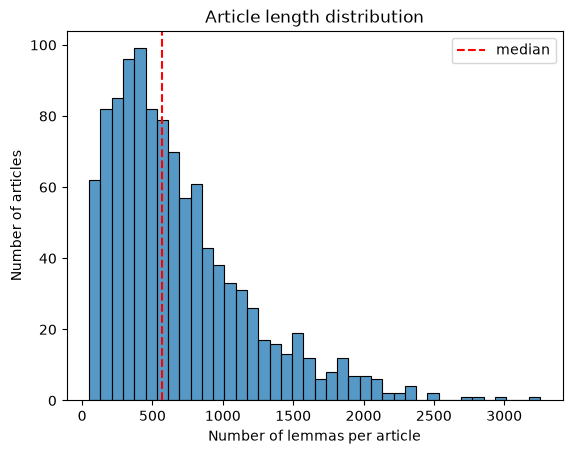

In [5]:
print(df["n_tokens"].describe())
sns.histplot(data=df, x="n_tokens", bins=40)
plt.title("Article length distribution")
plt.xlabel("Number of lemmas per article")
plt.ylabel("Number of articles")
plt.axvline(df["n_tokens"].median(), color="red", linestyle="--", label="median")
plt.legend()
plt.show()


### 1. Article Length Distribution

- Distribution is right-skewed.
- Half of the articles contain fewer than ~570 lemmas.
- Long tail up to ~3200 lemmas.

Text(0, 0.5, 'Lemma')

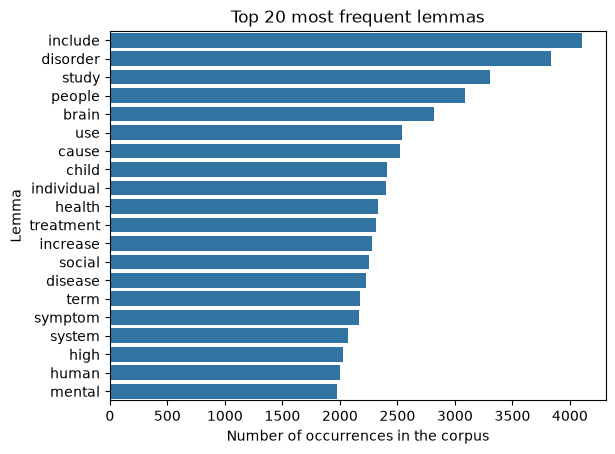

In [6]:
from collections import Counter

words = " ".join(df["lemmas"]).split()
counts = Counter(words)

top = pd.DataFrame(counts.most_common(20), columns=["word", "count"])
sns.barplot(data=top, x="count", y="word")
plt.title("Top 20 most frequent lemmas")
plt.xlabel("Number of occurrences in the corpus")
plt.ylabel("Lemma")


### 2. Most frequent lemmas

- The most frequent lemma is *include*. Like *use* or *cause*, it is a generic verb
  that says little about the topics of psychiatry and neuroscience.
- Apart from these generic verbs, domain words (*disorder*, *brain*, *symptom*, *mental*,
  *treatment*) dominate the top 20 lemmas, confirming that the corpus is focused
  on the aforementioned fields.
- *Disorder* appears more often than *disease*: psychiatric conditions are usually called
  *disorders* (DSM terminology), while *disease* is used mainly for neurological
  conditions such as *Alzheimer's disease*. This reflects that the corpus is more
  psychiatric than neurological.
- Raw frequency is not a good measure of word importance; TF-IDF should down-weight
  generic words.


### Zipf's law

**Zipf's law** states that the frequency of a word is inversely proportional
to its rank in the frequency list:

$$f(r) \approx \frac{C}{r}$$

where $f(r)$ is the frequency of the word at rank $r$ and $C$ is a constant
(roughly the frequency of the most common word).
On a log-log plot this relationship appears as a straight line with slope $-1$.
In information retrieval this means that a few words occur extremely often
but carry little information, while most of the vocabulary consists of rare words.


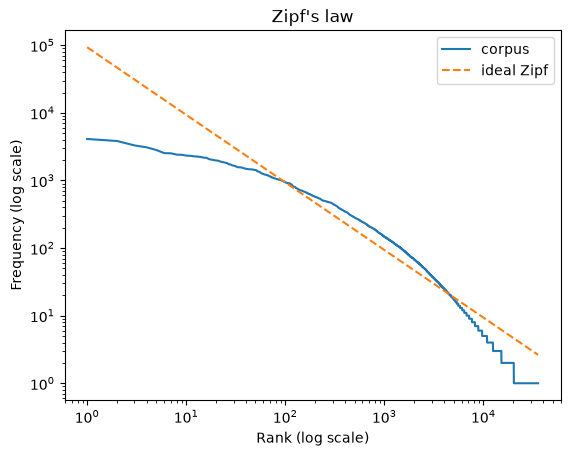

35557 distinct lemmas, 15355 (43.18%) of which appear only once
745264 lemma occurrences in total


In [7]:
freqs = sorted(counts.values(), reverse=True)
ranks = range(1, len(freqs) + 1)

plt.loglog(ranks, freqs, label="corpus")
plt.title("Zipf's law")
plt.xlabel("Rank (log scale)")
plt.ylabel("Frequency (log scale)")
C = freqs[99] * 100                     
plt.loglog(ranks, [C / r for r in ranks], "--", label="ideal Zipf")
plt.legend()
plt.show()

appear_once = sum(1 for c in counts.values() if c == 1)
print(f"{len(counts)} distinct lemmas, {appear_once} ({(appear_once/len(counts))*100:.2f}%) of which appear only once")
print(f"{sum(counts.values())} lemma occurrences in total")

#### Observations

- The corpus contains **745,264** lemma occurrences and **35,557** distinct lemmas.
- **Top ranks (1–100):** the curve lies below the ideal Zipf line. The most frequent
  words of English (*the*, *of*, *and*) were removed as stop words during preprocessing,
  so the head of the distribution is flattened.
- **Middle ranks (~100–5,000):** the curve closely follows the ideal line,
  so the corpus obeys Zipf's law in this range.
- **Low ranks (above ~5,000):** the curve drops faster than the ideal line,
  most likely because lemmatization merges inflected forms into one lemma
  and because the corpus is relatively small.
- **15,355 lemmas (43.18%) appear only once.** Such words receive the highest IDF weight,
  but many of them are rare names or noise.


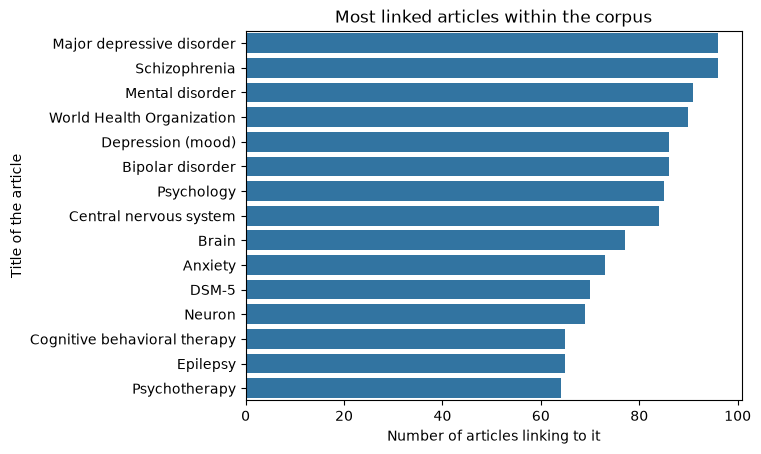

In [8]:
all_links = df["links"].explode()
in_db = all_links[all_links.isin(df["url"])]
top = in_db.value_counts().head(15)

url_to_name = dict(zip(df["url"], df["title"]))
names = top.index.map(url_to_name)

link_names = pd.DataFrame({"title": names, "count": top.values})
sns.barplot(data=link_names, x="count", y="title")
plt.title("Most linked articles within the corpus")
plt.xlabel("Number of articles linking to it")
plt.ylabel("Title of the article")
plt.show()

### 3. Most linked articles

- *Major depressive disorder* and *Schizophrenia* are the most linked articles in the corpus,
  with almost identical counts. Depression is one of the most common mental disorders
  and often co-occurs with other conditions, so many articles refer to it.
- This partly reflects the crawling strategy: both are seed articles, so many articles
  were discovered through their links and naturally link back to them.
- *World Health Organization* is the only organization in the top 15. Articles on mental
  disorders frequently cite WHO data on prevalence and treatment.
- General fields such as *Psychology* and *Psychotherapy*, as well as *DSM-5*
  (the main diagnostic manual in psychiatry, often called its "bible"), rank high,
  showing that the corpus is centred on psychiatry and clinical psychology.


(1081, 17010)
0    Attention deficit hyperactivity disorder
1                   Major depressive disorder
2                            Bipolar disorder
3                               Schizophrenia
4                                      Autism
5                Generalized anxiety disorder
6              Post-traumatic stress disorder
7                         Alzheimer's disease
8                                    Epilepsy
Name: title, dtype: str


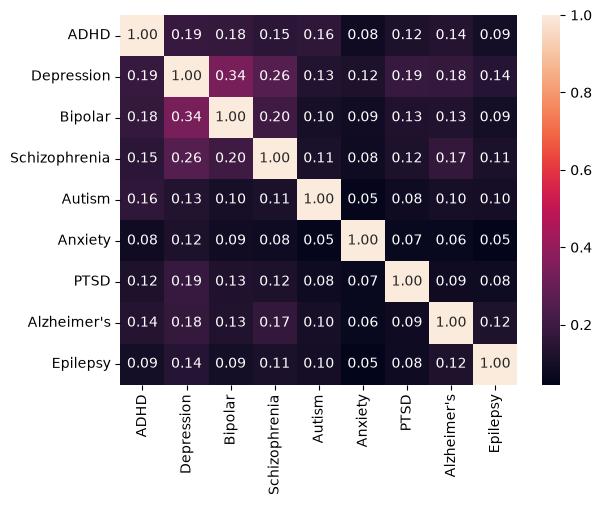

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

vec = TfidfVectorizer(min_df=2)
X = vec.fit_transform(df["lemmas"])
print(X.shape)
print(df["title"][:9])


labels = ["ADHD", "Depression", "Bipolar", "Schizophrenia", "Autism",
          "Anxiety", "PTSD", "Alzheimer's", "Epilepsy"]

sim = cosine_similarity(X[:9])
sns.heatmap(sim, annot=True, fmt=".2f", xticklabels=labels, yticklabels=labels)

plt.show()


### 4. Similarity between seed articles

- The most similar pair is *Major depressive disorder* and *Bipolar disorder* (0.34).
  This is expected: bipolar disorder includes depressive episodes, so both articles
  share a large part of their vocabulary.
- *Generalized anxiety disorder* is the most isolated article, with the lowest similarity
  to all others (e.g. 0.05 with *Autism*). Clinically, however, anxiety is very common
  in autistic people and frequently co-occurs with depression. The low scores show that
  **textual similarity does not equal clinical relatedness**: the articles simply
  use different vocabulary.
- Surprisingly, *ADHD* and *Autism* are only moderately similar (0.16), even though
  both are neurodevelopmental disorders.
- Overall, the similarity values are low (0.05–0.34). Each article contains many
  topic-specific words, so TF-IDF vectors overlap only partially. For recommendations,
  the absolute values matter less than the **ranking** of articles.


In [10]:
import numpy as np
import plotly.express as px
from matplotlib.colors import to_hex
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE

# 1. Reduce TF-IDF to 50 dims, then to 2D with t-SNE
small = TruncatedSVD(n_components=50, random_state=43).fit_transform(X)
xy = TSNE(n_components=2, metric="cosine", random_state=43).fit_transform(small)

# 2. Colour = most similar seed; "Off-topic" if similarity to every seed is very low
sims = cosine_similarity(X, X[:9])
best = sims.argmax(axis=1)
mx = sims.max(axis=1)

names = np.array(labels)[best]
groups = np.where(mx < 0.04, "Off-topic", names)

palette = dict(zip(labels, sns.color_palette("husl", 9)))
palette["Off-topic"] = "lightgray"
hex_palette = {k: to_hex(v) for k, v in palette.items()}

# 3. Interactive map (plotly) – hover to see titles
map_df = pd.DataFrame({
    "x": xy[:, 0],
    "y": xy[:, 1],
    "title": df["title"],
    "group": groups,
    "similarity": mx,
})

fig = px.scatter(
    map_df, x="x", y="y", color="group",
    hover_name="title",
    hover_data={"similarity": ":.2f", "x": False, "y": False},
    color_discrete_map=hex_palette,
    title="Interactive t-SNE map of all articles (hover to see titles)",
    width=900, height=650,
)
fig.update_traces(marker_size=5)
fig.update_xaxes(visible=False)
fig.update_yaxes(visible=False)
fig.show()

### 5. t-SNE map of all articles

- Each point is one article. The TF-IDF vectors were reduced to 50 dimensions with TruncatedSVD and then projected to 2D with t-SNE (cosine metric).
- The colour shows the most similar seed article. Articles whose similarity to every seed is below 0.04 are marked as *Off-topic*.
- *Autism* and *Epilepsy* form compact, well-separated clusters: their articles share a distinctive vocabulary.
- The map also reveals clusters that are not seed topics, for example one about brain injuries (*traumatic brain injury*, *CTE*, *American football*).
- Grey *Off-topic* points (e.g. *Santa Claus*, *Elmo*, *Cat*) come from BFS drift: the crawler followed links that led away from psychiatry. About 79% of articles are on topic. This is a limitation of the crawling step.

## Step 4 – Recommendation and explanation

This section describes how recommendations and their scores are computed (section 6), shows example results, and explains each score with a per-word breakdown (section 7).

### 6. Recommender

**How the score is computed:**
1. Each article is represented as a TF-IDF vector of its lemmas (`min_df=2`, 17,010 terms). The vectors are L2-normalised.
2. The **user profile** is the mean of the TF-IDF vectors of the visited articles.
3. **Score** = cosine similarity between the profile and every article in the database (0 = no shared terms, 1 = identical term distribution).
4. Visited articles are excluded, and the top-*k* articles by score are returned.

The logic lives in `wiki_recommender/recommender.py` (class `WikiRecommender`).

In [11]:
import sys
sys.path.append("..")

from wiki_recommender.recommender import WikiRecommender

recommender = WikiRecommender(df)
print(recommender.X.shape)

(1081, 17010)


#### Example 1 – single article (ADHD)

In [12]:
recommender.recommend(["Attention deficit hyperactivity disorder"])

,title,url,score
0,Adult attention deficit hyperactivity disorder,https://en.wikipedia.org/wiki/Adult_attention_...,0.838203
1,ADHD Rating Scale,https://en.wikipedia.org/wiki/ADHD_Rating_Scale,0.740891
2,Vanderbilt ADHD Diagnostic Rating Scale,https://en.wikipedia.org/wiki/Vanderbilt_ADHD_...,0.579574
3,Keith Conners,https://en.wikipedia.org/wiki/Keith_Conners,0.453667
4,Conners Comprehensive Behaviour Rating Scale,https://en.wikipedia.org/wiki/Conners_Comprehe...,0.434983
5,Russell Barkley,https://en.wikipedia.org/wiki/Russell_Barkley,0.411998
6,Child psychopathology,https://en.wikipedia.org/wiki/Child_psychopath...,0.359315
7,George Frederic Still,https://en.wikipedia.org/wiki/George_Still,0.280747
8,Disruptive Behavior Disorders Rating Scale,https://en.wikipedia.org/wiki/Disruptive_Behav...,0.273644
9,Oppositional defiant disorder,https://en.wikipedia.org/wiki/Oppositional_def...,0.252717


All ten recommendations are about ADHD. The top results are Adult ADHD (0.84) and two ADHD rating scales. The list also includes people and history: researchers Keith Conners and Russell Barkley, and George Frederic Still, who first described the disorder in 1902. It ends with Oppositional defiant disorder, a common comorbidity. So TF-IDF does more than match the same topic. It also finds the tools, people and related conditions linked to that topic, because these articles share rare, specific terms such as *conners*, *hyperactivity* and *rating*. One limitation: biographies appear among the results, and they may be less useful for a reader who wants to learn about the disorder itself.

#### Example 2 – two articles (ADHD + Autism)

In [13]:
recommender.recommend(["Attention deficit hyperactivity disorder", "Autism"])

,title,url,score
0,Adult attention deficit hyperactivity disorder,https://en.wikipedia.org/wiki/Adult_attention_...,0.638871
1,Management of autism,https://en.wikipedia.org/wiki/Autism_therapies,0.556679
2,ADHD Rating Scale,https://en.wikipedia.org/wiki/ADHD_Rating_Scale,0.554202
3,Autistic rights movement,https://en.wikipedia.org/wiki/Autism_rights_mo...,0.514178
4,Epidemiology of autism,https://en.wikipedia.org/wiki/Epidemiology_of_...,0.468134
5,Autistic masking,https://en.wikipedia.org/wiki/Autistic_masking,0.445540
6,Employment of autistic people,https://en.wikipedia.org/wiki/Employment_of_au...,0.443553
7,Vanderbilt ADHD Diagnostic Rating Scale,https://en.wikipedia.org/wiki/Vanderbilt_ADHD_...,0.442723
8,Sex and gender differences in autism,https://en.wikipedia.org/wiki/Sex_and_gender_d...,0.441274
9,Neurodiversity,https://en.wikipedia.org/wiki/Neurodiversity,0.428846


The profile is the mean of the two TF-IDF vectors, so it represents a mix of both topics. The scores are lower than in Example 1 (top score 0.64 vs 0.84), because no single article matches the mixed profile as closely. The results are unbalanced: 6 of 10 are about autism and only 3 are about ADHD. A likely reason is that the database contains more autism articles, and they are textually very similar to each other (they formed a compact cluster in the t-SNE map). Neurodiversity (#10) is the only recommendation that connects both topics. Both visited articles get the same cosine score with the profile (0.763). This is expected: every TF-IDF vector has unit length, so their mean lies at the same angle from each of them.

**Conclusion.** The averaged profile works well for one topic. With several topics, it leans towards the one that has more similar articles in the database. A possible improvement is to recommend separately for each visited article and then merge the lists, so that every topic is represented.

### 7. Prediction breakdown

Cosine similarity between the profile $p$ and an article $a$ is

$$\text{score}(p, a) = \frac{\sum_w p_w \, a_w}{\lVert p \rVert \, \lVert a \rVert}$$

Every TF-IDF article vector has unit length ($\lVert a \rVert = 1$), so the score is an exact **sum of per-word contributions**:

$$\text{score}(p, a) = \sum_w \underbrace{\frac{p_w}{\lVert p \rVert} \, a_w}_{\text{contribution of word } w}$$

A word contributes a lot only if it is important **both** in the user profile and in the recommended article. The method `WikiRecommender.explain()` returns these contributions. The charts below show the 10 largest contributions for each of the top-3 recommendations. The grey bar is the sum of all remaining words, so the bars add up exactly to the score.

In [14]:
BAR = "#2a78d6"
REST = "#c3c2b7"


def plot_breakdown(visited, k=3, top_n=10):
    """Per-word contributions to the score of the top-k recommendations."""
    recs = recommender.recommend(visited, k=k)
    fig, axes = plt.subplots(k, 1, figsize=(8, 3.4 * k), sharex=True)
    axes = np.atleast_1d(axes)

    for i, (ax, row) in enumerate(zip(axes, recs.itertuples())):
        parts = recommender.explain(visited, row.title, top_n=top_n)
        rest = row.score - parts["contribution"].sum()

        terms = list(parts["term"]) + ["(all other words)"]
        values = list(parts["contribution"]) + [rest]
        colors = [BAR] * len(parts) + [REST]

        ax.barh(terms, values, color=colors, height=0.6)
        ax.invert_yaxis()
        ax.set_title(f"#{i + 1}  {row.title}   (score = {row.score:.3f})", loc="left", fontsize=10)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="x", alpha=0.3)
        ax.set_axisbelow(True)

    axes[-1].set_xlabel("Contribution to the cosine score")
    fig.suptitle("Visited: " + ", ".join(visited), x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()

#### Breakdown – Example 1 (ADHD)

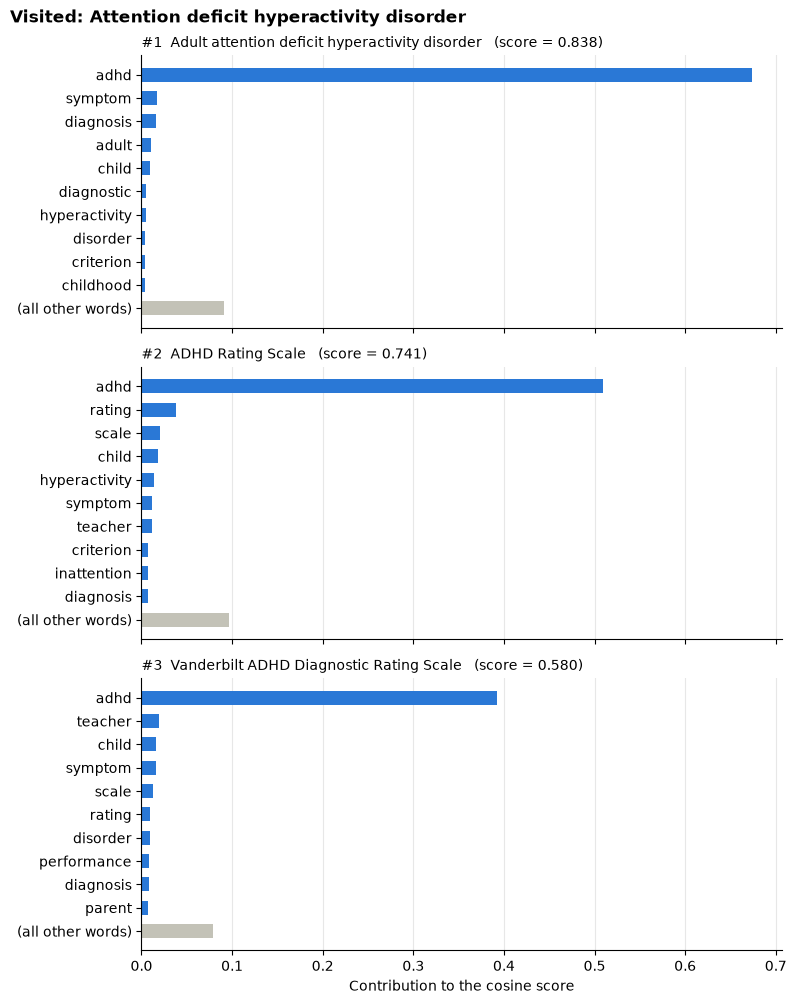

In [15]:
plot_breakdown(["Attention deficit hyperactivity disorder"])

#### Breakdown – Example 2 (ADHD + Autism)

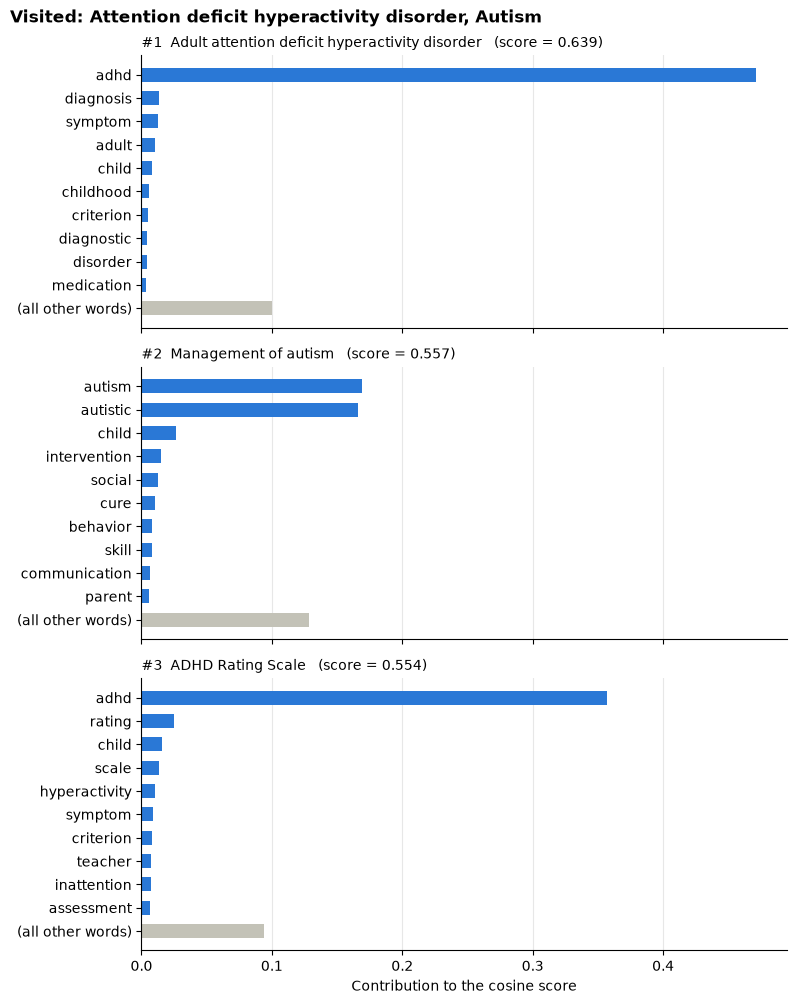

In [16]:
plot_breakdown(["Attention deficit hyperactivity disorder", "Autism"])

#### Observations

- **One word dominates the score.** For the top recommendations for ADHD, the term *adhd* alone accounts for roughly 70–80% of the score (e.g. 0.67 of 0.84 for *Adult ADHD*). A word gets a large contribution only when it has a high weight in both vectors: *adhd* is repeated many times in these articles (high TF) and appears almost only in ADHD-related articles (high IDF). In contrast, *disorder* occurs in most of the corpus, so its IDF is low and its contribution is tiny.
- **Lemmatization keeps *autism* and *autistic* apart.** For *Management of autism*, the two terms contribute almost equally. They share the same root, but lemmatization only removes inflection (*disorders → disorder*), not derivation (*autism → autistic*). As a result, one concept is split into two TF-IDF features.
- **The top 10 words explain most of the score.** The grey bar sums the contributions of all remaining ~17,000 words. Each of them adds very little, and together they make up only about 10–25% of the score. So the top-10 chart is a faithful explanation of the recommendation.
- **Implication for the recommender.** Because raw term frequency grows linearly, a single keyword can decide the ranking, and the system behaves almost like a keyword search for *adhd*. This gives very precise but not very diverse recommendations. A possible improvement is sublinear TF scaling (`sublinear_tf=True`, i.e. $1 + \log(tf)$), which reduces the dominance of frequently repeated words.
